In [1]:
import sys; sys.path.insert(0, '../..')
from paths import ROOT, DATA, STEPS, PREPARES, FIGURES, OUTPUT, CODE


In [2]:
import warnings
warnings.filterwarnings('ignore')

import h5py
import pickle
import scipy
import numpy as np
import seaborn as sns
# sns.set()
sns.set_style("whitegrid", {'axes.grid' : False})
import matplotlib.pyplot as plt
import matplotlib.image as mpimg
import pandas as pd
from os.path import join as pjoin
import scipy.io as sio
from scipy import stats
import scipy.signal as sp
from scipy import signal
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans

from statannot import add_stat_annotation
from skimage import io
from skimage.feature import hog
from joblib import Parallel, delayed
import cv2
import glob
import time
# from skimage.registration import phase_cross_correlation
from scipy.ndimage import fourier_shift
from joblib import Parallel, delayed
from skimage.feature import hog
import sys
sys.path.insert(1, str(CODE / 'make_0_prepare' / 'common-functions'))
from load_everything import *
from harness import *
import pickle

from IPython.display import display, clear_output, HTML, Image
from matplotlib import animation, rc

from skimage.measure import regionprops

from matplotlib import cm as mpl_cm
from matplotlib import (colors,
                        lines,
                        transforms,
                        )

from f2_utils import *
import time_in_each_roi
import matplotlib.patches as patches
import time_in_each_roi
from sklearn.linear_model import MultiTaskLassoCV,LassoCV
from sklearn.metrics import mean_squared_error,r2_score
from sklearn.model_selection import train_test_split


In [3]:
mice = ['cm229', 'cm219']
prefix = '/mnt/staging/'
fetch_path = str(PREPARES / "modeling") + "/"
fetch_path_sensory = str(PREPARES / "index-S1") + "/"
fetch_path_m1 = str(PREPARES / "index-M1") + "/"
fetch_path_m2 = str(PREPARES / "index-M2") + "/"
step_0_root = str(STEPS / "step_0") + "/"



Processing cm229
  ✓ cm229_10_runC: 420 rest + 76 loco = 496 combined (4 pairs)
  ✓ cm229_10_runD: 477 rest + 271 loco = 748 combined (4 pairs)
  ✓ cm229_10_runI: 547 rest + 173 loco = 720 combined (6 pairs)
  ✓ cm229_11_runC: 465 rest + 116 loco = 581 combined (5 pairs)
  ✓ cm229_11_runD: 741 rest + 157 loco = 898 combined (7 pairs)
  ✓ cm229_11_runE: 1145 rest + 224 loco = 1369 combined (12 pairs)
  ✓ cm229_11_runF: 541 rest + 139 loco = 680 combined (6 pairs)
  ✓ cm229_11_runG: 472 rest + 65 loco = 537 combined (4 pairs)
  ✓ cm229_11_runK: 573 rest + 298 loco = 871 combined (7 pairs)
  ✓ cm229_1_runC: 927 rest + 272 loco = 1199 combined (7 pairs)
  ✓ cm229_1_runD: 519 rest + 54 loco = 573 combined (3 pairs)
  ✓ cm229_1_runF: 1555 rest + 309 loco = 1864 combined (9 pairs)
  ✓ cm229_1_runG: 1093 rest + 230 loco = 1323 combined (8 pairs)
  ✓ cm229_1_runH: 521 rest + 95 loco = 616 combined (4 pairs)
  ✓ cm229_1_runI: 568 rest + 134 loco = 702 combined (4 pairs)
  ✓ cm229_1_runJ: 609 re

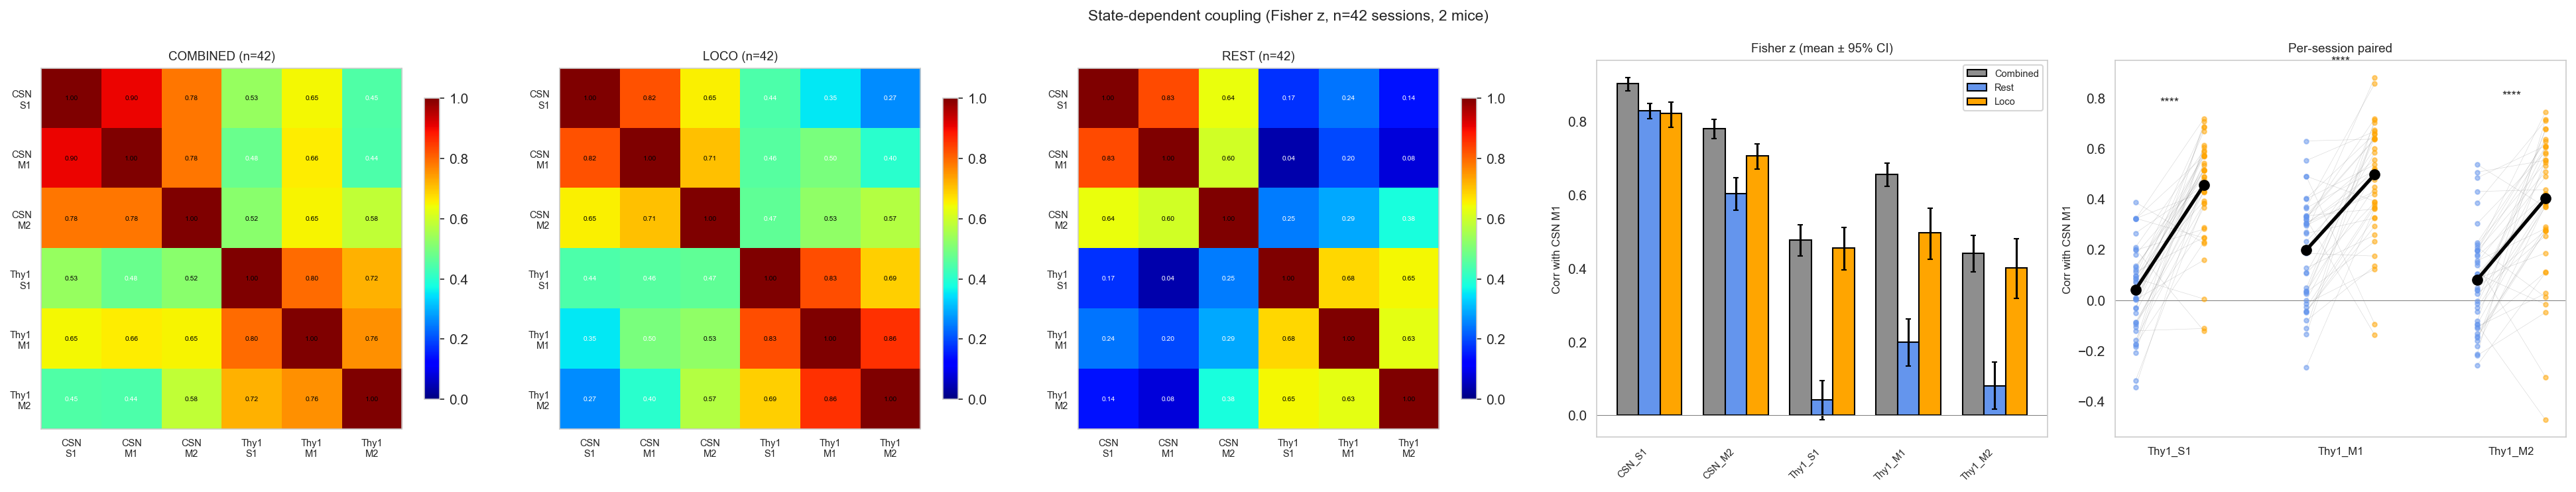

In [4]:
"""
Cardinal Signal Analysis Pipeline (Fisher z only)
===================================================
Three conditions:
  - Combined: rest + loco frames together (overall coupling)
  - Rest: rest frames only (spontaneous fluctuation regime)
  - Loco: loco frames only (movement-driven regime)

Pipeline:
  1. Bout detection → rest/loco pairing → frame extraction
  2. Fisher z-averaged matrices + stats (all three conditions)
  3. Plots (matrices, bar chart, paired dots)
"""

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.ndimage import median_filter, binary_closing
from scipy.stats import wilcoxon, friedmanchisquare


# ══════════════════════════════════════════════════════════════════
# HELPER FUNCTIONS
# ══════════════════════════════════════════════════════════════════

def find_bouts(mask_array, min_length):
    bouts = []
    in_bout = False
    start = 0
    for i in range(len(mask_array)):
        if mask_array[i]:
            if not in_bout:
                start = i
                in_bout = True
        else:
            if in_bout:
                if (i - start) >= min_length:
                    bouts.append((start, i))
                in_bout = False
    if in_bout and (len(mask_array) - start) >= min_length:
        bouts.append((start, len(mask_array)))
    return bouts

def fisher_z(r):
    return np.arctanh(np.clip(r, -0.999, 0.999))

def fisher_r(z):
    return np.tanh(z)

def fisher_z_matrix(corr_mat):
    z_mat = fisher_z(corr_mat)
    np.fill_diagonal(z_mat, np.nan)
    return z_mat

def fisher_r_matrix(z_mat):
    r_mat = fisher_r(z_mat)
    np.fill_diagonal(r_mat, 1.0)
    return r_mat


# ══════════════════════════════════════════════════════════════════
# PARAMETERS
# ══════════════════════════════════════════════════════════════════

FACE_SMOOTH_WINDOW   = 15
REST_GAP_FILL        = 20
MIN_REST_BOUT        = 90
REST_TRIM_ONSET      = 30
FACE_REST_PERCENTILE = 30
FACE_REST_CAP        = 0.1

LOCO_BODY_THRESH     = 0.2
LOCO_RAMP_THRESH     = 0.05
MIN_LOCO_BOUT        = 15

MAX_GAP_REST_TO_LOCO = 500

MIN_REST_FRAMES      = 100
MIN_LOCO_FRAMES      = 15

CHANNEL_NAMES = ['CSN_S1', 'CSN_M1', 'CSN_M2', 'Thy1_S1', 'Thy1_M1', 'Thy1_M2']
CARDINAL_IDX  = 1
TEST_CHANNELS = ['CSN_S1', 'CSN_M2', 'Thy1_S1', 'Thy1_M1', 'Thy1_M2']
THY1_CHANNELS = ['Thy1_S1', 'Thy1_M1', 'Thy1_M2']
STATES        = ['combined', 'rest', 'loco']


# ══════════════════════════════════════════════════════════════════
# STEP 1: EXTRACT DATA
# ══════════════════════════════════════════════════════════════════

def process_all_sessions(mice, fetch_path, fetch_path_sensory, fetch_path_m1, fetch_path_m2, load_model):

    all_z_matrices = {'combined': [], 'rest': [], 'loco': []}
    session_corrs = []

    for mouse in mice:
        print(f"\n{'='*50}")
        print(f"Processing {mouse}")

        data_joint = load_model(fetch_path + mouse + '_data_joint.pickle')
        data_joint_filtered = data_joint[data_joint['is_groom'] <= 0.01].copy()

        sensory_ind = load_model(fetch_path_sensory + 'brightest_ind_' + mouse)
        M2_ind = load_model(fetch_path_m2 + 'brightest_frontline_ind-' + mouse)
        if mouse == 'cm229':
            M1_ind = load_model(fetch_path_m1 + 'M1_ind_' + mouse)
        elif mouse == 'cm219':
            M1_ind = {'RFP': 315}

        thy1_s1_idx = sensory_ind['RFP']
        thy1_m1_idx = M1_ind['RFP']
        thy1_m2_idx = M2_ind['RFP']
        csn_s1_idx  = sensory_ind['RFP'] + 500
        csn_m1_idx  = M1_ind['RFP'] + 500
        csn_m2_idx  = M2_ind['RFP'] + 500
        col_indices = [csn_s1_idx, csn_m1_idx, csn_m2_idx,
                       thy1_s1_idx, thy1_m1_idx, thy1_m2_idx]

        all_sessions = list(np.unique(data_joint_filtered.index.get_level_values(0)))

        for session in all_sessions:
            session_data = data_joint_filtered.loc[session]
            face_raw = session_data['face_pc'].values
            body = session_data['body_pc'].values

            face_smooth = median_filter(face_raw, size=FACE_SMOOTH_WINDOW)
            face_thresh = min(
                np.nanpercentile(face_smooth, FACE_REST_PERCENTILE),
                FACE_REST_CAP
            )
            rest_mask = face_smooth < face_thresh
            rest_mask = binary_closing(rest_mask, structure=np.ones(REST_GAP_FILL))
            loco_mask = body > LOCO_BODY_THRESH

            rest_bouts = find_bouts(rest_mask, MIN_REST_BOUT)
            loco_bouts = find_bouts(loco_mask, MIN_LOCO_BOUT)

            extended_loco_bouts = []
            for ls, le in loco_bouts:
                ramp_start = ls
                while ramp_start > 0 and body[ramp_start - 1] > LOCO_RAMP_THRESH:
                    ramp_start -= 1
                extended_loco_bouts.append((ramp_start, le))
            loco_bouts = extended_loco_bouts

            paired_segments = []
            used_rest = set()
            for ls, le in loco_bouts:
                best_rest, best_gap, best_idx = None, float('inf'), None
                for j, (rs, re) in enumerate(rest_bouts):
                    if j in used_rest:
                        continue
                    gap = ls - re
                    if 0 <= gap < best_gap:
                        best_gap, best_rest, best_idx = gap, (rs, re), j
                if best_rest is not None and best_gap <= MAX_GAP_REST_TO_LOCO:
                    paired_segments.append({'rest': best_rest, 'loco': (ls, le)})
                    used_rest.add(best_idx)

            if len(paired_segments) == 0:
                continue

            rest_indices, loco_indices = [], []
            for p in paired_segments:
                rs, re = p['rest']
                ls, le = p['loco']
                trimmed_rs = rs + REST_TRIM_ONSET
                if trimmed_rs < re:
                    rest_indices.extend(range(trimmed_rs, re))
                    loco_indices.extend(range(ls, le))

            rest_indices = np.array(rest_indices)
            loco_indices = np.array(loco_indices)

            if len(rest_indices) < MIN_REST_FRAMES or len(loco_indices) < MIN_LOCO_FRAMES:
                continue

            def extract_signals(indices):
                d = session_data.iloc[indices]
                m = np.column_stack([d.iloc[:, c].values for c in col_indices])
                valid = ~np.isnan(m).any(axis=1)
                return m[valid]

            rest_clean = extract_signals(rest_indices)
            loco_clean = extract_signals(loco_indices)

            if len(rest_clean) < 50 or len(loco_clean) < 50:
                continue

            combined_clean = np.vstack([rest_clean, loco_clean])

            rest_corr = np.corrcoef(rest_clean, rowvar=False)
            loco_corr = np.corrcoef(loco_clean, rowvar=False)
            combined_corr = np.corrcoef(combined_clean, rowvar=False)

            all_z_matrices['rest'].append(fisher_z_matrix(rest_corr))
            all_z_matrices['loco'].append(fisher_z_matrix(loco_corr))
            all_z_matrices['combined'].append(fisher_z_matrix(combined_corr))

            row = {'Mouse': mouse, 'Session': session,
                   'n_rest': len(rest_clean), 'n_loco': len(loco_clean),
                   'n_combined': len(combined_clean), 'n_pairs': len(paired_segments)}

            for state, corr_mat in [('rest', rest_corr), ('loco', loco_corr), ('combined', combined_corr)]:
                for i, ch in enumerate(CHANNEL_NAMES):
                    if i == CARDINAL_IDX:
                        continue
                    row[f'{ch}_{state}_r'] = corr_mat[CARDINAL_IDX, i]
                    row[f'{ch}_{state}_z'] = fisher_z(corr_mat[CARDINAL_IDX, i])

            session_corrs.append(row)
            print(f"  ✓ {session}: {len(rest_clean)} rest + {len(loco_clean)} loco "
                  f"= {len(combined_clean)} combined ({len(paired_segments)} pairs)")

    corr_df = pd.DataFrame(session_corrs)

    fz_results = {'n_sessions': len(corr_df)}
    for state in STATES:
        z_arr = np.array(all_z_matrices[state])
        mean_z = np.nanmean(z_arr, axis=0)
        sem_z = np.nanstd(z_arr, axis=0) / np.sqrt(len(z_arr))
        fz_results[f'{state}_mean_r'] = fisher_r_matrix(mean_z)
        fz_results[f'{state}_mean_z'] = mean_z
        fz_results[f'{state}_ci_lo'] = fisher_r_matrix(mean_z - 1.96 * sem_z)
        fz_results[f'{state}_ci_hi'] = fisher_r_matrix(mean_z + 1.96 * sem_z)
        fz_results[f'{state}_all_z'] = z_arr

    print(f"\n{'='*50}")
    print(f"Total: {len(corr_df)} sessions")
    print(f"Per mouse: {corr_df.groupby('Mouse').size().to_dict()}")

    print(f"\n--- Fisher z-averaged correlation with CSN M1 ---")
    print(f"{'Channel':12s} {'Combined':>10s} {'Rest':>10s} {'Loco':>10s}")
    print("-" * 45)
    for i, ch in enumerate(CHANNEL_NAMES):
        if i == CARDINAL_IDX:
            continue
        vals = []
        for state in STATES:
            vals.append(fz_results[f'{state}_mean_r'][CARDINAL_IDX, i])
        print(f"{ch:12s} {vals[0]:10.3f} {vals[1]:10.3f} {vals[2]:10.3f}")

    return fz_results, corr_df


# ══════════════════════════════════════════════════════════════════
# STEP 2: FISHER Z STATS
# ══════════════════════════════════════════════════════════════════

def run_fisher_z_stats(corr_df):

    results = {}

    # ── STAT 1: REST vs LOCO ──────────────────────────────────────
    print("\n" + "=" * 70)
    print("STAT 1: REST vs LOCO coupling to CSN M1")
    print("  Paired Wilcoxon on Fisher z, one-sided (loco > rest)")
    print("=" * 70)
    print(f"{'Channel':12s} {'n':>4s} {'Combined':>10s} {'Rest r':>8s} {'Loco r':>8s} {'Δr':>6s} {'p':>12s}")
    print("-" * 65)

    stat1 = {}
    for ch in TEST_CHANNELS:
        rest_z = corr_df[f'{ch}_rest_z'].values
        loco_z = corr_df[f'{ch}_loco_z'].values
        combined_z = corr_df[f'{ch}_combined_z'].values
        stat, p = wilcoxon(loco_z, rest_z, alternative='greater')
        rest_r = fisher_r(np.mean(rest_z))
        loco_r = fisher_r(np.mean(loco_z))
        combined_r = fisher_r(np.mean(combined_z))
        stat1[ch] = {'n': len(rest_z), 'p': p,
                     'rest_r': rest_r, 'loco_r': loco_r, 'combined_r': combined_r}
        print(f"{ch:12s} {len(rest_z):4d} {combined_r:10.3f} {rest_r:8.3f} {loco_r:8.3f} "
              f"{loco_r - rest_r:6.3f} {p:12.2e}")
    results['stat1'] = stat1

    # ── STAT 2: REST vs zero ──────────────────────────────────────
    print("\n" + "=" * 70)
    print("STAT 2: REST correlation vs zero (Wilcoxon two-sided on z)")
    print("=" * 70)
    print(f"{'Channel':12s} {'n':>4s} {'Rest r':>8s} {'p':>12s} {'Sig':>5s}")
    print("-" * 42)

    for ch in TEST_CHANNELS:
        rest_z = corr_df[f'{ch}_rest_z'].values
        stat, p = wilcoxon(rest_z, alternative='two-sided')
        rest_r = fisher_r(np.mean(rest_z))
        sig = '****' if p < 0.0001 else '***' if p < 0.001 else '**' if p < 0.01 else '*' if p < 0.05 else 'ns'
        print(f"{ch:12s} {len(rest_z):4d} {rest_r:8.3f} {p:12.2e} {sig:>5s}")

    # ── STAT 3: Regional differences at REST (Friedman) ───────────
    print("\n" + "=" * 70)
    print("STAT 3: Thy1 regional differences at REST (Friedman + post-hoc)")
    print("=" * 70)

    s1_z = corr_df['Thy1_S1_rest_z'].values
    m1_z = corr_df['Thy1_M1_rest_z'].values
    m2_z = corr_df['Thy1_M2_rest_z'].values
    stat_f, p_f = friedmanchisquare(s1_z, m1_z, m2_z)
    print(f"Friedman: chi2={stat_f:.2f}, p={p_f:.2e}, n={len(corr_df)}")

    pairs = [('Thy1_S1', 'Thy1_M1'), ('Thy1_S1', 'Thy1_M2'), ('Thy1_M1', 'Thy1_M2')]
    print("Post-hoc Wilcoxon (Bonferroni-corrected):")
    for a, b in pairs:
        stat, p = wilcoxon(corr_df[f'{a}_rest_z'].values,
                           corr_df[f'{b}_rest_z'].values, alternative='two-sided')
        print(f"  {a} vs {b}: p_raw={p:.2e}, p_corr={min(p*3, 1.0):.2e}")

    # ── STAT 4: Regional differences at LOCO (Friedman) ───────────
    print("\n" + "=" * 70)
    print("STAT 4: Thy1 regional differences at LOCO (Friedman + post-hoc)")
    print("=" * 70)

    s1_z = corr_df['Thy1_S1_loco_z'].values
    m1_z = corr_df['Thy1_M1_loco_z'].values
    m2_z = corr_df['Thy1_M2_loco_z'].values
    stat_f, p_f = friedmanchisquare(s1_z, m1_z, m2_z)
    print(f"Friedman: chi2={stat_f:.2f}, p={p_f:.2e}, n={len(corr_df)}")

    print("Post-hoc Wilcoxon (Bonferroni-corrected):")
    for a, b in pairs:
        stat, p = wilcoxon(corr_df[f'{a}_loco_z'].values,
                           corr_df[f'{b}_loco_z'].values, alternative='two-sided')
        print(f"  {a} vs {b}: p_raw={p:.2e}, p_corr={min(p*3, 1.0):.2e}")

    # ── STAT 5: CSN vs Thy1 within region ─────────────────────────
    print("\n" + "=" * 70)
    print("STAT 5: CSN vs Thy1 within region (paired Wilcoxon on z)")
    print("=" * 70)

    for csn_ch, thy1_ch, region in [('CSN_S1', 'Thy1_S1', 'S1'), ('CSN_M2', 'Thy1_M2', 'M2')]:
        for state in STATES:
            csn_z = corr_df[f'{csn_ch}_{state}_z'].values
            thy1_z = corr_df[f'{thy1_ch}_{state}_z'].values
            stat, p = wilcoxon(csn_z, thy1_z, alternative='greater')
            print(f"  {region} {state.upper():>8s}: CSN r={fisher_r(np.mean(csn_z)):.3f} "
                  f"vs Thy1 r={fisher_r(np.mean(thy1_z)):.3f}, p={p:.2e}")

    # ── STAT 6: Effect sizes ──────────────────────────────────────
    print("\n" + "=" * 70)
    print("STAT 6: Cohen's d (on z-transformed loco − rest)")
    print("=" * 70)

    for ch in TEST_CHANNELS:
        diff_z = corr_df[f'{ch}_loco_z'].values - corr_df[f'{ch}_rest_z'].values
        d = np.mean(diff_z) / np.std(diff_z)
        print(f"  {ch:12s}: d = {d:.2f}")

    # ── SUMMARY TABLE ─────────────────────────────────────────────
    print("\n" + "=" * 70)
    print("MANUSCRIPT SUMMARY TABLE (Fisher z)")
    print("=" * 70)
    print(f"{'Channel':12s} {'n':>4s} {'Combined':>10s} {'Rest r':>8s} {'Loco r':>8s} {'Δr':>6s} "
          f"{'p (L>R)':>12s} {'Cohen d':>8s}")
    print("-" * 72)
    for ch in TEST_CHANNELS:
        s = stat1[ch]
        diff_z = corr_df[f'{ch}_loco_z'].values - corr_df[f'{ch}_rest_z'].values
        d = np.mean(diff_z) / np.std(diff_z)
        print(f"{ch:12s} {s['n']:4d} {s['combined_r']:10.3f} {s['rest_r']:8.3f} {s['loco_r']:8.3f} "
              f"{s['loco_r']-s['rest_r']:6.3f} {s['p']:12.2e} {d:8.2f}")

    return results


# ══════════════════════════════════════════════════════════════════
# STEP 3: PLOTS
# ══════════════════════════════════════════════════════════════════

def plot_all(corr_df, fz_results, fisher_stats):

    stat1 = fisher_stats['stat1']
    n_sess = fz_results['n_sessions']
    labels_short = ['CSN\nS1', 'CSN\nM1', 'CSN\nM2', 'Thy1\nS1', 'Thy1\nM1', 'Thy1\nM2']

    fig, axes = plt.subplots(1, 5, figsize=(26, 5), dpi=150)

    # Panels A-C: Combined / Loco / Rest matrices
    for ax, state, title in [(axes[0], 'combined', 'COMBINED'),
                              (axes[1], 'loco', 'LOCO'),
                              (axes[2], 'rest', 'REST')]:
        mat = fz_results[f'{state}_mean_r']
        im = ax.imshow(mat, vmin=0, vmax=1, cmap='jet')
        ax.set_xticks(range(6)); ax.set_yticks(range(6))
        ax.set_xticklabels(labels_short, fontsize=7)
        ax.set_yticklabels(labels_short, fontsize=7)
        plt.colorbar(im, ax=ax, shrink=0.8)
        ax.set_title(f'{title} (n={n_sess})', fontsize=9)
        for i in range(6):
            for j in range(6):
                ax.text(j, i, f'{mat[i,j]:.2f}', ha='center', va='center',
                        fontsize=5, color='white' if mat[i,j] < 0.5 else 'black')

    # Panel D: Grouped bar chart (3 conditions)
    ax = axes[3]
    x = np.arange(len(TEST_CHANNELS))
    width = 0.25
    colors = {'combined': '#8e8e8e', 'rest': 'cornflowerblue', 'loco': 'orange'}

    for k, state in enumerate(STATES):
        mr = fz_results[f'{state}_mean_r']
        clo = fz_results[f'{state}_ci_lo']
        chi_ = fz_results[f'{state}_ci_hi']
        vals = [mr[CARDINAL_IDX, CHANNEL_NAMES.index(ch)] for ch in TEST_CHANNELS]
        err_lo = [mr[CARDINAL_IDX, CHANNEL_NAMES.index(ch)] - clo[CARDINAL_IDX, CHANNEL_NAMES.index(ch)] for ch in TEST_CHANNELS]
        err_hi = [chi_[CARDINAL_IDX, CHANNEL_NAMES.index(ch)] - mr[CARDINAL_IDX, CHANNEL_NAMES.index(ch)] for ch in TEST_CHANNELS]
        ax.bar(x + (k - 1) * width, vals, width, yerr=[err_lo, err_hi],
               color=colors[state], edgecolor='k', capsize=2, label=state.capitalize())

    ax.set_xticks(x)
    ax.set_xticklabels(TEST_CHANNELS, rotation=45, ha='right', fontsize=7)
    ax.set_ylabel('Corr with CSN M1', fontsize=8)
    ax.set_title('Fisher z (mean ± 95% CI)', fontsize=9)
    ax.legend(fontsize=7)
    ax.axhline(0, color='gray', lw=0.5)

    # Panel E: Paired dot plot (Thy1 only, rest vs loco)
    ax = axes[4]
    for k, ch in enumerate(THY1_CHANNELS):
        rest_r = corr_df[f'{ch}_rest_r'].values
        loco_r = corr_df[f'{ch}_loco_r'].values
        x_rest = k * 2.5
        x_loco = k * 2.5 + 1

        for r, l in zip(rest_r, loco_r):
            ax.plot([x_rest, x_loco], [r, l], color='gray', lw=0.3, alpha=0.3)
        ax.scatter(np.full(len(rest_r), x_rest), rest_r,
                   color='cornflowerblue', s=10, alpha=0.5, zorder=3)
        ax.scatter(np.full(len(loco_r), x_loco), loco_r,
                   color='orange', s=10, alpha=0.5, zorder=3)

        rest_mean = fisher_r(np.mean(corr_df[f'{ch}_rest_z'].values))
        loco_mean = fisher_r(np.mean(corr_df[f'{ch}_loco_z'].values))
        ax.plot([x_rest, x_loco], [rest_mean, loco_mean],
                color='k', lw=2.5, zorder=4, marker='o', markersize=7)

        p = stat1[ch]['p']
        sig = '****' if p < 0.0001 else '***' if p < 0.001 else '**' if p < 0.01 else '*' if p < 0.05 else 'ns'
        y_max = max(np.max(rest_r), np.max(loco_r)) + 0.05
        ax.text((x_rest + x_loco) / 2, y_max, sig, ha='center', fontsize=9)

    ax.set_xticks([0.5, 3.0, 5.5])
    ax.set_xticklabels(THY1_CHANNELS, fontsize=8)
    ax.set_ylabel('Corr with CSN M1', fontsize=8)
    ax.set_title('Per-session paired', fontsize=9)
    ax.axhline(0, color='gray', lw=0.5)

    plt.suptitle(f'State-dependent coupling (Fisher z, n={n_sess} sessions, 2 mice)', fontsize=11)
    plt.tight_layout()
    plt.show()


# ══════════════════════════════════════════════════════════════════
# STEP 4: TIME COURSE INSPECTION
# ══════════════════════════════════════════════════════════════════

def plot_concatenated_timecourse(mice, fetch_path, fetch_path_sensory, fetch_path_m1, fetch_path_m2,
                                  load_model, which_mouse='cm229'):

    mouse = which_mouse
    data_joint = load_model(fetch_path + mouse + '_data_joint.pickle')
    data_joint_filtered = data_joint[data_joint['is_groom'] <= 0.01].copy()

    sensory_ind = load_model(fetch_path_sensory + 'brightest_ind_' + mouse)
    M2_ind = load_model(fetch_path_m2 + 'brightest_frontline_ind-' + mouse)
    if mouse == 'cm229':
        M1_ind = load_model(fetch_path_m1 + 'M1_ind_' + mouse)
    elif mouse == 'cm219':
        M1_ind = {'RFP': 315}

    col_indices = [sensory_ind['RFP'] + 500, M1_ind['RFP'] + 500, M2_ind['RFP'] + 500,
                   sensory_ind['RFP'], M1_ind['RFP'], M2_ind['RFP']]

    all_sessions = list(np.unique(data_joint_filtered.index.get_level_values(0)))
    all_signals = {name: [] for name in CHANNEL_NAMES}
    seg_info, sess_bounds = [], []
    cursor = 0

    for session in all_sessions:
        session_data = data_joint_filtered.loc[session]
        face_raw = session_data['face_pc'].values
        body = session_data['body_pc'].values

        face_smooth = median_filter(face_raw, size=FACE_SMOOTH_WINDOW)
        face_thresh = min(np.nanpercentile(face_smooth, FACE_REST_PERCENTILE), FACE_REST_CAP)
        rest_mask = face_smooth < face_thresh
        rest_mask = binary_closing(rest_mask, structure=np.ones(REST_GAP_FILL))
        loco_mask = body > LOCO_BODY_THRESH

        rest_bouts = find_bouts(rest_mask, MIN_REST_BOUT)
        loco_bouts = find_bouts(loco_mask, MIN_LOCO_BOUT)

        extended_loco_bouts = []
        for ls, le in loco_bouts:
            ramp_start = ls
            while ramp_start > 0 and body[ramp_start - 1] > LOCO_RAMP_THRESH:
                ramp_start -= 1
            extended_loco_bouts.append((ramp_start, le))
        loco_bouts = extended_loco_bouts

        paired_segments = []
        used_rest = set()
        for ls, le in loco_bouts:
            best_rest, best_gap, best_idx = None, float('inf'), None
            for j, (rs, re) in enumerate(rest_bouts):
                if j in used_rest:
                    continue
                gap = ls - re
                if 0 <= gap < best_gap:
                    best_gap, best_rest, best_idx = gap, (rs, re), j
            if best_rest is not None and best_gap <= MAX_GAP_REST_TO_LOCO:
                paired_segments.append({'rest': best_rest, 'loco': (ls, le)})
                used_rest.add(best_idx)

        if len(paired_segments) == 0:
            continue

        sess_start = cursor
        for p in paired_segments:
            rs, re = p['rest']
            ls, le = p['loco']
            trimmed_rs = rs + REST_TRIM_ONSET
            if trimmed_rs < re:
                n = re - trimmed_rs
                kept = session_data.iloc[trimmed_rs:re]
                for ci_idx, ch in enumerate(CHANNEL_NAMES):
                    all_signals[ch].append(kept.iloc[:, col_indices[ci_idx]].values)
                seg_info.append((cursor, cursor + n, 'rest'))
                cursor += n
            n = le - ls
            kept = session_data.iloc[ls:le]
            for ci_idx, ch in enumerate(CHANNEL_NAMES):
                all_signals[ch].append(kept.iloc[:, col_indices[ci_idx]].values)
            seg_info.append((cursor, cursor + n, 'loco'))
            cursor += n
        sess_bounds.append((sess_start, cursor, session))

    concat = {ch: np.concatenate(all_signals[ch]) for ch in CHANNEL_NAMES}
    colors_neural = ['#2ecc71', '#27ae60', '#1e8449', '#e74c3c', '#c0392b', '#922b21']

    fig, axes = plt.subplots(6, 1, figsize=(20, 12), sharex=True, dpi=150)
    for ax, ch, col in zip(axes, CHANNEL_NAMES, colors_neural):
        ax.plot(concat[ch], color=col, lw=0.3)
        ax.set_ylabel(ch, fontsize=9)
        ax.tick_params(labelsize=7)
        for s, e, label in seg_info:
            ax.axvspan(s, e, color='cornflowerblue' if label == 'rest' else 'orange', alpha=0.15)
        for s, e, _ in sess_bounds:
            ax.axvline(s, color='gray', ls='-', lw=0.3, alpha=0.5)

    axes[-1].set_xlabel('Concatenated frame')
    axes[0].set_title(f'{which_mouse} — kept frames ({len(sess_bounds)} sessions)')
    plt.tight_layout()
    plt.show()

    n_rest = sum(e - s for s, e, l in seg_info if l == 'rest')
    n_loco = sum(e - s for s, e, l in seg_info if l == 'loco')
    print(f"Total: {cursor} frames ({n_rest} rest + {n_loco} loco)")


# ══════════════════════════════════════════════════════════════════
# RUN EVERYTHING
# ══════════════════════════════════════════════════════════════════

# --- 1. Extract data ---
fz_results, corr_df = process_all_sessions(
    mice, fetch_path, fetch_path_sensory, fetch_path_m1, fetch_path_m2, load_model
)

# --- 2. Fisher z stats ---
fisher_stats = run_fisher_z_stats(corr_df)

# --- 3. Plots ---
plot_all(corr_df, fz_results, fisher_stats)

# --- 4. Time course (uncomment to run) ---
# plot_concatenated_timecourse(mice, fetch_path, fetch_path_sensory,
#                              fetch_path_m1, fetch_path_m2, load_model, 'cm229')

## Main Fig 5i - state-dependent inter-population coupling

Pearson r between the reference CSN M1 signal and five forepaw populations during locomotion, rest and combined epochs. 42 sessions from 2 mice. Two-sided Wilcoxon signed-rank test against r = 0, Benjamini-Hochberg corrected within each state.


--- Statistical Results (Wilcoxon signed-rank vs 0, FDR Corrected) ---
CSN
S1 (Rest): raw_p=4.55e-13, fdr_p=1.14e-12 -> ****
CSN
M2 (Rest): raw_p=4.55e-13, fdr_p=1.14e-12 -> ****
Thy1
S1 (Rest): raw_p=1.55e-01, fdr_p=1.55e-01 -> n.s.
Thy1
M1 (Rest): raw_p=2.30e-06, fdr_p=3.83e-06 -> ****
Thy1
M2 (Rest): raw_p=4.60e-02, fdr_p=5.75e-02 -> n.s.
------------------------------------------------------


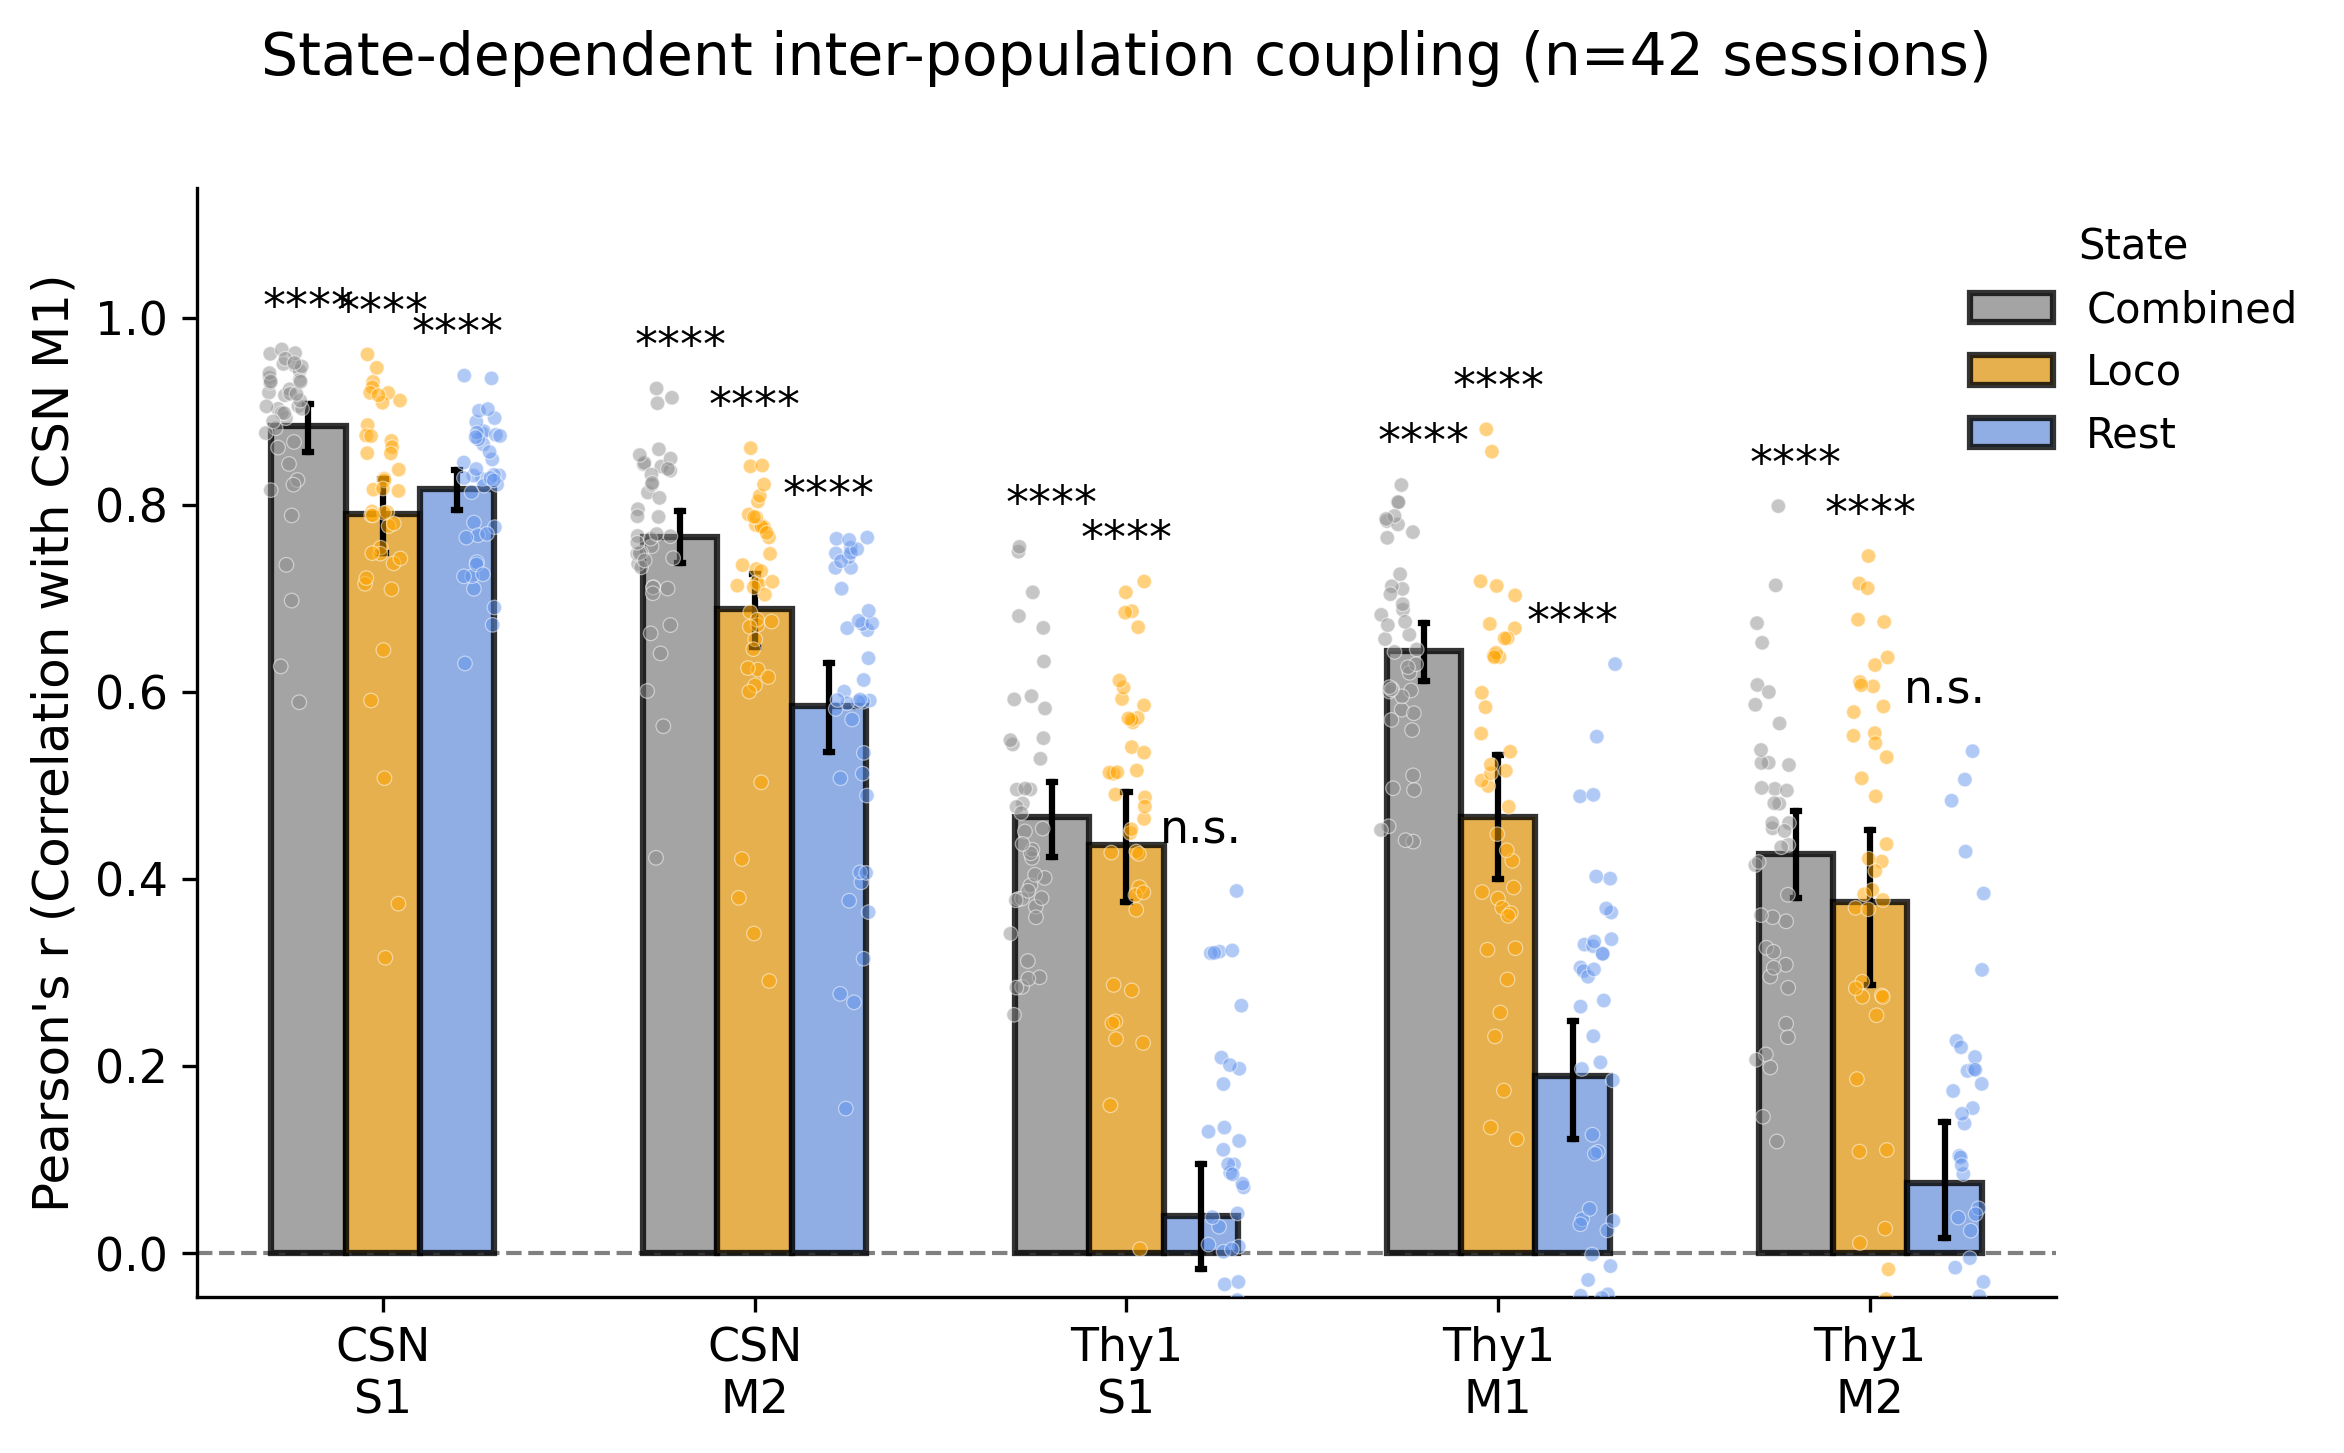

In [5]:
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np
from scipy import stats
import pandas as pd
from matplotlib.gridspec import GridSpec
from statsmodels.stats.multitest import multipletests

# === 1. Data Preparation ===
# Assuming `corr_df` is already loaded in your environment from the pipeline
TEST_CHANNELS = ['CSN_S1', 'CSN_M2', 'Thy1_S1', 'Thy1_M1', 'Thy1_M2']
STATES = ['combined', 'loco', 'rest'] # Updated logical order

# Melt corr_df into a long-format DataFrame for Seaborn
plot_data = []
for index, row in corr_df.iterrows():
    for ch in TEST_CHANNELS:
        for state in STATES:
            plot_data.append({
                'Channel': ch.replace('_', '\n'),
                'State': state.capitalize(),
                'Correlation': row[f'{ch}_{state}_r'], # Swapped back to Pearson's r
                'Session_ID': index
            })

df_plot = pd.DataFrame(plot_data)

state_order = ['Combined', 'Loco', 'Rest']
my_pal = {'Combined': '#8e8e8e', 'Loco': 'orange', 'Rest': 'cornflowerblue'}

# === 2. Figure Setup & Plotting ===
plt.style.use('default')
plt.rcParams['svg.fonttype'] = 'none'
fig = plt.figure(figsize=(10, 6), dpi=300)
gs = GridSpec(100, 100)

ax0 = fig.add_subplot(gs[10:90, 10:90])

# Barplot (Narrower bars using width=0.6)
sns.barplot(x="Channel", y="Correlation", hue="State", hue_order=state_order, palette=my_pal,
            data=df_plot, errorbar=('ci', 95), capsize=0.05, errcolor='black', errwidth=1.5,
            linewidth=1.5, edgecolor='black', alpha=0.8, width=0.6, ax=ax0, zorder=2)

# Stripplot (Jitter dots)
sns.stripplot(x="Channel", y="Correlation", hue="State", hue_order=state_order, palette=my_pal,
              data=df_plot, dodge=True, size=3.5, alpha=0.5, zorder=3, ax=ax0, 
              edgecolor='white', linewidth=0.3, jitter=0.15)

# Fix Legends (stripplot adds duplicate handles)
handles, labels = ax0.get_legend_handles_labels()
ax0.legend(handles[:3], labels[:3], loc='upper right', bbox_to_anchor=(1.15, 1), 
           title="State", frameon=False, fontsize=10)

ax0.axhline(0, color='gray', linewidth=1.0, linestyle='dashed', zorder=0)

# === 3. Statistics (Wilcoxon vs 0, FDR Corrected) & Annotation ===
print("--- Statistical Results (Wilcoxon signed-rank vs 0, FDR Corrected) ---")

num_channels = len(TEST_CHANNELS)
channels_formatted = [ch.replace('_', '\n') for ch in TEST_CHANNELS]

for j, state in enumerate(state_order):
    raw_pvals = []
    subset_data_list = []
    
    # First pass: collect all raw p-values for this specific state
    for i, ch_label in enumerate(channels_formatted):
        subset_data = df_plot[(df_plot['Channel'] == ch_label) & (df_plot['State'] == state)]['Correlation'].values
        stat, p_val = stats.wilcoxon(subset_data, alternative='two-sided')
        raw_pvals.append(p_val)
        subset_data_list.append(subset_data)
        
    # Apply Benjamini-Hochberg FDR correction across the 5 channels
    reject, pvals_corrected, _, _ = multipletests(raw_pvals, alpha=0.05, method='fdr_bh')
    
    # Second pass: apply stars and text based on the CORRECTED p-values
    for i, ch_label in enumerate(channels_formatted):
        p_corr = pvals_corrected[i]
        subset_data = subset_data_list[i]
        
        if p_corr < 0.0001: sig_str = "****"
        elif p_corr < 0.001: sig_str = "***"
        elif p_corr < 0.01: sig_str = "**"
        elif p_corr < 0.05: sig_str = "*"
        else: sig_str = "n.s."
        
        # Log to console to verify against pipeline output
        if state == 'Rest':
            print(f"{ch_label.replace('xx', '_')} (Rest): raw_p={raw_pvals[i]:.2e}, fdr_p={p_corr:.2e} -> {sig_str}")
        
        # Find the exact bar patch to get its X center
        bar_idx = j * num_channels + i
        bar = ax0.patches[bar_idx]
        x_center = bar.get_x() + bar.get_width() / 2
        
        # Position the text slightly above the maximum jitter point for this specific bar
        y_max = subset_data.max()
        text_offset = 0.04 if sig_str == "n.s." else 0.02 # Slightly smaller offsets for the -1 to 1 scale
        
        ax0.text(x_center, y_max + text_offset, sig_str, ha='center', va='bottom', 
                 color='black', fontsize=11, zorder=5)

print("------------------------------------------------------")

# === 4. Axis formatting ===
ax0.set_ylabel("Pearson's r (Correlation with CSN M1)", fontsize=12)
ax0.set_xlabel('')
ax0.set_title(f'State-dependent inter-population coupling (n={len(corr_df)} sessions)', y=1.08, fontsize=14)

# Aesthetic cleanup
ax0.spines['top'].set_visible(False)
ax0.spines['right'].set_visible(False)
ax0.tick_params(axis='x', labelsize=11)
ax0.tick_params(axis='y', labelsize=11)

# Expand Y limit slightly to make room for the stars so they don't clip on the tighter r-scale
current_bottom, current_top = ax0.get_ylim()
ax0.set_ylim([current_bottom+0.5, current_top + 0.1])

plt.savefig('fig5-Barplot_StatsVsZero_PearsonR.svg', format='svg', dpi=300, bbox_inches='tight')
plt.show()

In [6]:
from statsmodels.stats.multitest import multipletests
from scipy.stats import wilcoxon

CHANNEL_NAMES = ['CSN_S1', 'CSN_M1', 'CSN_M2', 'Thy1_S1', 'Thy1_M1', 'Thy1_M2']
labels_short = ['CSN\nS1', 'CSN\nM1', 'CSN\nM2', 'Thy1\nS1', 'Thy1\nM1', 'Thy1\nM2']

n_sess = fz_results['n_sessions']

# Run stats for all three conditions
conditions = {
    'REST':       (fz_results['rest_all_z'],     fz_results['rest_mean_r']),
    'LOCOMOTION': (fz_results['loco_all_z'],     fz_results['loco_mean_r']),
    'COMBINED':   (fz_results['combined_all_z'], fz_results['combined_mean_r']),
}

# Store p-value matrices per condition for later use
p_matrices = {}

def sig_stars(p):
    if p < 0.0001: return '****'
    if p < 0.001:  return '***'
    if p < 0.01:   return '**'
    if p < 0.05:   return '*'
    return 'ns'

for cond_name, (all_z, mean_r) in conditions.items():
    pair_indices = []
    pair_pvals_raw = []
    pair_stats = []

    for i in range(6):
        for j in range(i+1, 6):
            vals = all_z[:, i, j]
            vals_clean = vals[~np.isnan(vals)]
            if len(vals_clean) > 5:
                stat, p = wilcoxon(vals_clean, alternative='two-sided')
            else:
                stat, p = np.nan, 1.0
            pair_indices.append((i, j))
            pair_pvals_raw.append(p)
            pair_stats.append(stat)

    # FDR (Benjamini-Hochberg) and Bonferroni correction across the 15 pairs
    reject_fdr, pvals_fdr, _, _ = multipletests(pair_pvals_raw, method='fdr_bh')
    reject_bonf, pvals_bonf, _, _ = multipletests(pair_pvals_raw, method='bonferroni')

    # Build full p-value matrices
    p_raw_mat = np.ones((6, 6))
    p_fdr_mat = np.ones((6, 6))
    p_bonf_mat = np.ones((6, 6))

    for k, (i, j) in enumerate(pair_indices):
        p_raw_mat[i, j]  = p_raw_mat[j, i]  = pair_pvals_raw[k]
        p_fdr_mat[i, j]  = p_fdr_mat[j, i]  = pvals_fdr[k]
        p_bonf_mat[i, j] = p_bonf_mat[j, i] = pvals_bonf[k]

    p_matrices[cond_name] = {
        'p_raw': p_raw_mat,
        'p_fdr': p_fdr_mat,
        'p_bonf': p_bonf_mat,
    }

    # Print
    print("=" * 85)
    print(f"{cond_name} correlation vs zero: per-cell Wilcoxon signed-rank (two-sided)")
    print(f"n = {n_sess} sessions, 15 unique pairs, FDR (Benjamini-Hochberg) corrected")
    print("=" * 85)
    print(f"{'Pair':25s} {'r':>6s} {'p_raw':>10s} {'p_FDR':>10s} {'p_Bonf':>10s} {'Sig(FDR)':>10s}")
    print("-" * 75)

    for k, (i, j) in enumerate(pair_indices):
        r_val = mean_r[i, j]
        p_raw = pair_pvals_raw[k]
        p_fdr = pvals_fdr[k]
        p_bonf = pvals_bonf[k]
        sig = sig_stars(p_fdr)
        print(f"  {CHANNEL_NAMES[i]:10s} × {CHANNEL_NAMES[j]:10s} {r_val:6.3f} "
              f"{p_raw:10.2e} {p_fdr:10.2e} {p_bonf:10.2e} {sig:>10s}")
    print()

# Backwards compatibility: keep the old rest_p_fdr name if other code uses it
rest_p_fdr  = p_matrices['REST']['p_fdr']
rest_p_raw  = p_matrices['REST']['p_raw']
rest_p_bonf = p_matrices['REST']['p_bonf']

# Also expose the new ones for consistency
loco_p_fdr     = p_matrices['LOCOMOTION']['p_fdr']
combined_p_fdr = p_matrices['COMBINED']['p_fdr']

REST correlation vs zero: per-cell Wilcoxon signed-rank (two-sided)
n = 42 sessions, 15 unique pairs, FDR (Benjamini-Hochberg) corrected
Pair                           r      p_raw      p_FDR     p_Bonf   Sig(FDR)
---------------------------------------------------------------------------
  CSN_S1     × CSN_M1      0.829   4.55e-13   9.74e-13   6.82e-12       ****
  CSN_S1     × CSN_M2      0.636   4.55e-13   9.74e-13   6.82e-12       ****
  CSN_S1     × Thy1_S1     0.172   3.25e-07   4.43e-07   4.88e-06       ****
  CSN_S1     × Thy1_M1     0.241   1.96e-09   2.94e-09   2.94e-08       ****
  CSN_S1     × Thy1_M2     0.144   2.56e-05   2.96e-05   3.84e-04       ****
  CSN_M1     × CSN_M2      0.604   4.55e-13   9.74e-13   6.82e-12       ****
  CSN_M1     × Thy1_S1     0.041   1.55e-01   1.55e-01   1.00e+00         ns
  CSN_M1     × Thy1_M1     0.199   2.30e-06   2.87e-06   3.45e-05       ****
  CSN_M1     × Thy1_M2     0.081   4.60e-02   4.93e-02   6.90e-01          *
  CSN_M2     × Th

## Suppl Fig 6b - pairwise correlation matrices

**This cell produces a panel of Supplementary Figure 6, not Figure 5.** Per-session matrices Fisher z-transformed, averaged across the 42 sessions, back-transformed to r for display; the fourth panel is FDR-corrected p-values across the 15 unique pairs.

It lives here because it shares this notebook's pipeline output (`fz_results`); the output is named `figS6b-` so the panel can be found.


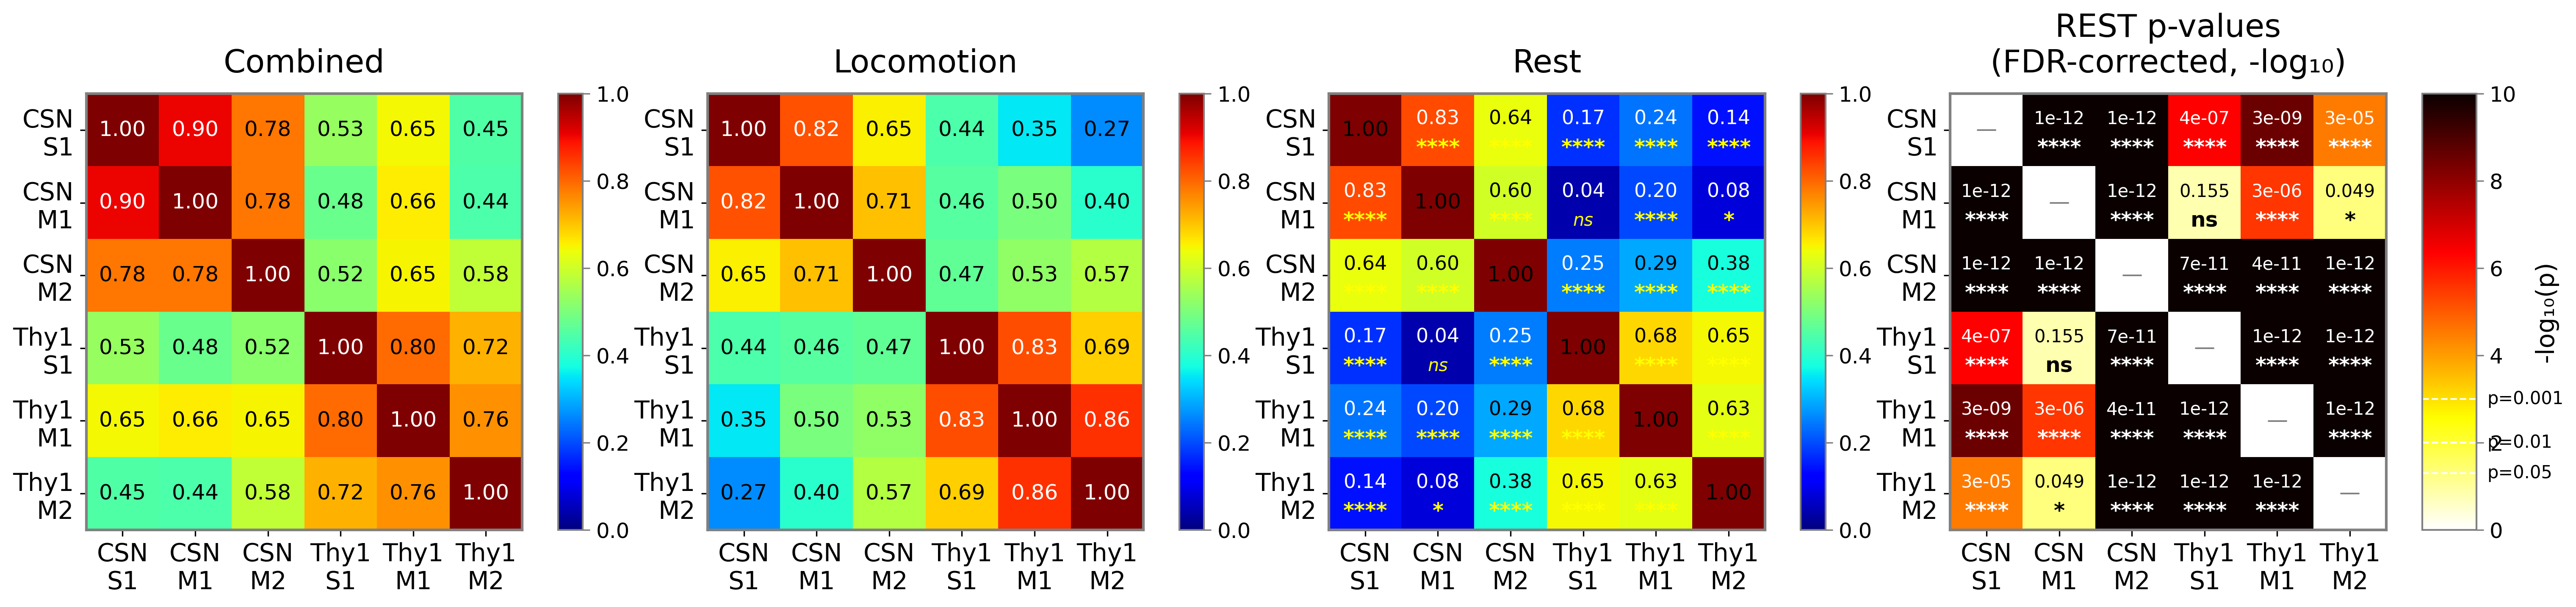

In [7]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.colors as colors
from matplotlib import ticker
from matplotlib.gridspec import GridSpec



# ══════════════════════════════════════════════════════════════════
# 1. SETUP & FIGURE INITIALIZATION
# ══════════════════════════════════════════════════════════════════
plt.style.use('default')
plt.rcParams['svg.fonttype'] = 'none'

fig = plt.figure(figsize=(30, 30), dpi=300)
gs = GridSpec(100, 100)

y_offset = 40
size = 15
cb_gap = 1
x_gap = 4
x_start = 5

axes = []
caxes = []

# Dynamically slice GridSpec: make the 4th colorbar wider
for i in range(4):
    ax = fig.add_subplot(gs[y_offset : y_offset + size, x_start : x_start + size])
    axes.append(ax)
    
    # Make the rightmost colorbar wider (width 2 instead of 1)
    cb_width = 2 if i == 3 else 1
    cax = fig.add_subplot(gs[y_offset : y_offset + size, x_start + size + cb_gap : x_start + size + cb_gap + cb_width])
    caxes.append(cax)
    
    x_start += (size + cb_gap + cb_width + x_gap)

# ── Helper for Jet contrast ───────────────────────────────────────
def get_jet_contrast_color(val):
    # Jet is dark at the extremes (<0.25 is dark blue, >0.8 is dark red)
    return 'white' if (val < 0.25 or val > 0.8) else 'black'

# ══════════════════════════════════════════════════════════════════
# 2. PLOT MATRICES
# ══════════════════════════════════════════════════════════════════

# ── Panel 0: COMBINED ─────────────────────────────────────────────
mat = fz_results['combined_mean_r']
im0 = axes[0].imshow(mat, vmin=0, vmax=1, cmap='jet')
axes[0].set_title('Combined', fontsize=18, pad=12)
for i in range(6):
    for j in range(6):
        c = get_jet_contrast_color(mat[i, j])
        axes[0].text(j, i, f'{mat[i,j]:.2f}', ha='center', va='center',
                     fontsize=12, color=c)

# ── Panel 1: LOCOMOTION ───────────────────────────────────────────
mat = fz_results['loco_mean_r']
im1 = axes[1].imshow(mat, vmin=0, vmax=1, cmap='jet')
axes[1].set_title('Locomotion', fontsize=18, pad=12)
for i in range(6):
    for j in range(6):
        c = get_jet_contrast_color(mat[i, j])
        axes[1].text(j, i, f'{mat[i,j]:.2f}', ha='center', va='center',
                     fontsize=12, color=c)

# ── Panel 2: REST (with stats) ────────────────────────────────────
mat = fz_results['rest_mean_r']
im2 = axes[2].imshow(mat, vmin=0, vmax=1, cmap='jet')
axes[2].set_title('Rest', fontsize=18, pad=12)
for i in range(6):
    for j in range(6):
        if i == j:
            axes[2].text(j, i, '1.00', ha='center', va='center', fontsize=12, color='black')
            continue
        r_val = mat[i, j]
        stars = sig_stars(rest_p_fdr[i, j])
        c = get_jet_contrast_color(r_val)
        
        # Push r-value slightly up, stars slightly down for larger text fit
        axes[2].text(j, i - 0.15, f'{r_val:.2f}', ha='center', va='center', fontsize=11, color=c)
        
        if stars == 'ns':
            axes[2].text(j, i + 0.25, stars, ha='center', va='center',
                         fontsize=10, color='yellow', fontstyle='italic')
        else:
            axes[2].text(j, i + 0.25, stars, ha='center', va='center',
                         fontsize=12, color='yellow', fontweight='bold')

# ── Panel 3: P-VALUE MATRIX ───────────────────────────────────────
log_p = -np.log10(np.clip(rest_p_fdr, 1e-20, 1))
np.fill_diagonal(log_p, 0)
im3 = axes[3].imshow(log_p, vmin=0, vmax=10, cmap='hot_r')
axes[3].set_title('REST p-values\n(FDR-corrected, -log₁₀)', fontsize=18, pad=12)

for i in range(6):
    for j in range(6):
        if i == j:
            axes[3].text(j, i, '—', ha='center', va='center', fontsize=12, color='gray')
            continue
        p_val = rest_p_fdr[i, j]
        stars = sig_stars(p_val)
        
        # Hot_R goes from white(0) -> yellow -> red -> black(10)
        c = 'white' if log_p[i, j] > 4.5 else 'black'
        
        p_str = f'{p_val:.0e}' if p_val < 0.001 else f'{p_val:.3f}'
        axes[3].text(j, i - 0.15, p_str, ha='center', va='center', fontsize=10, color=c)
        axes[3].text(j, i + 0.25, stars, ha='center', va='center',
                     fontsize=12, color=c, fontweight='bold')

# ══════════════════════════════════════════════════════════════════
# 3. COLORBARS & STYLING 
# ══════════════════════════════════════════════════════════════════
images = [im0, im1, im2, im3]

for i, (im, cax) in enumerate(zip(images, caxes)):
    cb = fig.colorbar(im, cax=cax, orientation='vertical')
    
    cb.ax.tick_params(labelsize=12, length=4, color='gray') 
    cb.ax.yaxis.tick_right() 
    cb.outline.set_edgecolor('gray')
    cb.outline.set_linewidth(1)
    
    tick_locator = ticker.MaxNLocator(nbins=5)
    cb.locator = tick_locator
    cb.update_ticks()
    
    cax.set_aspect('auto') # Let GridSpec handle the proportions natively
    
    if i == 3: 
        cb.set_label('-log₁₀(p)', fontsize=14, labelpad=10)
        for thresh, label in [(1.3, 'p=0.05'), (2, 'p=0.01'), (3, 'p=0.001')]:
            cb.ax.axhline(thresh, color='white', lw=1, ls='--')
            # Pin the threshold text to the right side of the colorbar correctly
            cb.ax.text(1.2, thresh, label, fontsize=10, va='center', ha='left', transform=cb.ax.get_yaxis_transform())

# ── Shared axes formatting ────────────────────────────────────────
for ax in axes:
    ax.set_xticks(range(6))
    ax.set_yticks(range(6))
    ax.set_xticklabels(labels_short, fontsize=14)
    ax.set_yticklabels(labels_short, fontsize=14)
    
    for spine in ax.spines.values():
        spine.set_edgecolor('gray')
        spine.set_linewidth(1.5)
plt.savefig('figS6b-correlation-matrices.svg', format='svg', dpi=300)
plt.show()

In [8]:
from scipy.stats import wilcoxon
from statsmodels.stats.multitest import multipletests
import numpy as np

# Channel order: ['CSN_S1', 'CSN_M1', 'CSN_M2', 'Thy1_S1', 'Thy1_M1', 'Thy1_M2']
# Indices:         0         1          2          3           4          5

CHANNEL_NAMES = ['CSN_S1', 'CSN_M1', 'CSN_M2', 'Thy1_S1', 'Thy1_M1', 'Thy1_M2']

# Use Fisher z-transformed values for stats (more appropriate for correlation comparison)
combined_z = fz_results['combined_all_z']  # (n_sessions, 6, 6)
combined_r = fz_results['combined_mean_r']

# Reference: CSN_M1 (index 1)
ref_idx = 1
ref_name = CHANNEL_NAMES[ref_idx]

# Comparisons we want: CSN_M1 × Thy1_M1 vs. CSN_M1 × {Thy1_S1, Thy1_M2}
# In matrix terms: [ref_idx, 4] vs. [ref_idx, 3] and [ref_idx, 5]

target_thy1_m1 = 4   # Thy1_M1
targets_others = [3, 5]  # Thy1_S1, Thy1_M2

print("=" * 90)
print(f"Paired Wilcoxon: {ref_name} × Thy1_M1 vs. {ref_name} × {{Thy1_S1, Thy1_M2}}")
print(f"n = {combined_z.shape[0]} sessions, on Fisher z-transformed correlations (combined epochs)")
print("=" * 90)

pvals = []
labels = []

for j_other in targets_others:
    z_thy1m1 = combined_z[:, ref_idx, target_thy1_m1]
    z_other  = combined_z[:, ref_idx, j_other]
   
    mask = ~(np.isnan(z_thy1m1) | np.isnan(z_other))
    z_thy1m1_clean = z_thy1m1[mask]
    z_other_clean  = z_other[mask]
   
    stat, p = wilcoxon(z_thy1m1_clean, z_other_clean, alternative='two-sided')
   
    r_thy1m1 = combined_r[ref_idx, target_thy1_m1]
    r_other  = combined_r[ref_idx, j_other]
   
    label = f"{ref_name}×Thy1_M1 vs. {ref_name}×{CHANNEL_NAMES[j_other]}"
    print(f"  {label}")
    print(f"    r = {r_thy1m1:.3f} vs. {r_other:.3f}  (mean diff = {r_thy1m1 - r_other:+.3f})")
    print(f"    W = {stat:.1f}, p_raw = {p:.2e}, n = {len(z_thy1m1_clean)} sessions")
   
    pvals.append(p)
    labels.append(label)

# FDR correction across the 2 comparisons
_, pvals_fdr, _, _ = multipletests(pvals, method='fdr_bh')

print("\nWith FDR (Benjamini-Hochberg) correction across 2 comparisons:")
for label, p_raw, p_fdr in zip(labels, pvals, pvals_fdr):
    sig = '****' if p_fdr < 0.0001 else '***' if p_fdr < 0.001 else '**' if p_fdr < 0.01 else '*' if p_fdr < 0.05 else 'ns'
    print(f"  {label}: p_FDR = {p_fdr:.2e} {sig}")
    
# Also test: CSN_M1 × CSN_S1 vs. CSN_M1 × CSN_M2
z_csn_s1 = combined_z[:, ref_idx, 0]
z_csn_m2 = combined_z[:, ref_idx, 2]
mask = ~(np.isnan(z_csn_s1) | np.isnan(z_csn_m2))
stat, p = wilcoxon(z_csn_s1[mask], z_csn_m2[mask], alternative='two-sided')
r_s1 = combined_r[ref_idx, 0]
r_m2 = combined_r[ref_idx, 2]
print(f"\n  CSN_M1×CSN_S1 vs. CSN_M1×CSN_M2")
print(f"    r = {r_s1:.3f} vs. {r_m2:.3f}  (mean diff = {r_s1 - r_m2:+.3f})")
print(f"    W = {stat:.1f}, p = {p:.2e}, n = {mask.sum()} sessions")

Paired Wilcoxon: CSN_M1 × Thy1_M1 vs. CSN_M1 × {Thy1_S1, Thy1_M2}
n = 42 sessions, on Fisher z-transformed correlations (combined epochs)
  CSN_M1×Thy1_M1 vs. CSN_M1×Thy1_S1
    r = 0.656 vs. 0.478  (mean diff = +0.178)
    W = 0.0, p_raw = 4.55e-13, n = 42 sessions
  CSN_M1×Thy1_M1 vs. CSN_M1×Thy1_M2
    r = 0.656 vs. 0.442  (mean diff = +0.215)
    W = 10.0, p_raw = 1.96e-11, n = 42 sessions

With FDR (Benjamini-Hochberg) correction across 2 comparisons:
  CSN_M1×Thy1_M1 vs. CSN_M1×Thy1_S1: p_FDR = 9.09e-13 ****
  CSN_M1×Thy1_M1 vs. CSN_M1×Thy1_M2: p_FDR = 1.96e-11 ****

  CSN_M1×CSN_S1 vs. CSN_M1×CSN_M2
    r = 0.904 vs. 0.781  (mean diff = +0.122)
    W = 9.0, p = 1.50e-11, n = 42 sessions
